# RTT — EDA

First look at the 96 monthly RTT csvs (Apr 2018 – Mar 2026) produced by `01_fetch_dataset`.

| section | question it answers |
|---|---|
| 1. Load one month | what does a single month's csv look like |
| 2. Columns & structure | what fields it carries, which are numeric |
| 3. Numeric summary | scale and spread of the week-band counts |
| 4. Missing values | which columns are empty and how often |
| 5. File inventory | what's on disk, how many files |
| 6. Month coverage | is every month Apr 2018 → Mar 2026 present |
| 7. Column formats | do all 96 files share one schema (spoiler: 69 vs 121) |
| 8. Build the monthly panel | all 96 files → one row per (month, provider, specialty) |
| 9. Panel coverage | how many providers/specialties, does the panel drift |
| 10. National trend | waiting list size and long-wait shares over 8 years |
| 11. Provider × specialty | one concrete series at modeling granularity |
| 12. Pre vs post Covid | how much worse did it get |
| 13. Core file | save `data/processed/rtt_incomplete_panel.csv` |

## 1. Load one month

One file first — learn the shape before touching all 96.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

filePath = "../data/rtt_csv/20191031-RTT-OCTOBER-2019-full-extract.csv"
df = pd.read_csv(filePath)

print("Shape : ", df.shape)
df.info()
df.head(10)

Shape :  (204136, 69)
<class 'pandas.DataFrame'>
RangeIndex: 204136 entries, 0 to 204135
Data columns (total 69 columns):
 #   Column                                  Non-Null Count   Dtype  
---  ------                                  --------------   -----  
 0   Period                                  204136 non-null  str    
 1   Provider Parent Org Code                204136 non-null  str    
 2   Provider Parent Name                    204136 non-null  str    
 3   Provider Org Code                       204136 non-null  str    
 4   Provider Org Name                       204136 non-null  str    
 5   Commissioner Parent Org Code            196196 non-null  str    
 6   Commissioner Parent Name                196196 non-null  str    
 7   Commissioner Org Code                   204136 non-null  str    
 8   Commissioner Org Name                   201564 non-null  str    
 9   RTT Part Type                           204136 non-null  str    
 10  RTT Part Description             

,Period,Provider Parent Org Code,Provider Parent Name,Provider Org Code,Provider Org Name,Commissioner Parent Org Code,Commissioner Parent Name,Commissioner Org Code,Commissioner Org Name,RTT Part Type,...,Gt 46 To 47 Weeks SUM 1,Gt 47 To 48 Weeks SUM 1,Gt 48 To 49 Weeks SUM 1,Gt 49 To 50 Weeks SUM 1,Gt 50 To 51 Weeks SUM 1,Gt 51 To 52 Weeks SUM 1,Gt 52 Weeks SUM 1,Total,Patients with unknown clock start date,Total All
0,RTT-OCTOBER-2019,Q71,NHS ENGLAND LONDON,DX1,THE NEW FOSCOTE HOSPITAL LTD,Q77,NHS ENGLAND MIDLANDS (WEST MIDLANDS),05F,NHS HEREFORDSHIRE CCG,Part_1B,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1
1,RTT-OCTOBER-2019,Q71,NHS ENGLAND LONDON,DX1,THE NEW FOSCOTE HOSPITAL LTD,Q77,NHS ENGLAND MIDLANDS (WEST MIDLANDS),05F,NHS HEREFORDSHIRE CCG,Part_1B,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1
2,RTT-OCTOBER-2019,Q71,NHS ENGLAND LONDON,DX1,THE NEW FOSCOTE HOSPITAL LTD,Q77,NHS ENGLAND MIDLANDS (WEST MIDLANDS),05F,NHS HEREFORDSHIRE CCG,Part_3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
3,RTT-OCTOBER-2019,Q71,NHS ENGLAND LONDON,DX1,THE NEW FOSCOTE HOSPITAL LTD,Q77,NHS ENGLAND MIDLANDS (WEST MIDLANDS),05F,NHS HEREFORDSHIRE CCG,Part_3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
4,RTT-OCTOBER-2019,Q71,NHS ENGLAND LONDON,DX1,THE NEW FOSCOTE HOSPITAL LTD,Q77,NHS ENGLAND MIDLANDS (WEST MIDLANDS),05R,NHS SOUTH WARWICKSHIRE CCG,Part_1A,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1
5,RTT-OCTOBER-2019,Q71,NHS ENGLAND LONDON,DX1,THE NEW FOSCOTE HOSPITAL LTD,Q77,NHS ENGLAND MIDLANDS (WEST MIDLANDS),05R,NHS SOUTH WARWICKSHIRE CCG,Part_1A,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1
6,RTT-OCTOBER-2019,Q71,NHS ENGLAND LONDON,DX1,THE NEW FOSCOTE HOSPITAL LTD,Q77,NHS ENGLAND MIDLANDS (WEST MIDLANDS),05R,NHS SOUTH WARWICKSHIRE CCG,Part_1B,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1
7,RTT-OCTOBER-2019,Q71,NHS ENGLAND LONDON,DX1,THE NEW FOSCOTE HOSPITAL LTD,Q77,NHS ENGLAND MIDLANDS (WEST MIDLANDS),05R,NHS SOUTH WARWICKSHIRE CCG,Part_1B,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1
8,RTT-OCTOBER-2019,Q71,NHS ENGLAND LONDON,DX1,THE NEW FOSCOTE HOSPITAL LTD,Q77,NHS ENGLAND MIDLANDS (WEST MIDLANDS),05R,NHS SOUTH WARWICKSHIRE CCG,Part_2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,3
9,RTT-OCTOBER-2019,Q71,NHS ENGLAND LONDON,DX1,THE NEW FOSCOTE HOSPITAL LTD,Q77,NHS ENGLAND MIDLANDS (WEST MIDLANDS),05R,NHS SOUTH WARWICKSHIRE CCG,Part_2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,1


## 2. Columns & structure

In [2]:
print(df.columns.tolist())

columns_to_check = df.columns[:] 
df[columns_to_check].head()


['Period', 'Provider Parent Org Code', 'Provider Parent Name', 'Provider Org Code', 'Provider Org Name', 'Commissioner Parent Org Code', 'Commissioner Parent Name', 'Commissioner Org Code', 'Commissioner Org Name', 'RTT Part Type', 'RTT Part Description', 'Treatment Function Code', 'Treatment Function Name', 'Gt 00 To 01 Weeks SUM 1', 'Gt 01 To 02 Weeks SUM 1', 'Gt 02 To 03 Weeks SUM 1', 'Gt 03 To 04 Weeks SUM 1', 'Gt 04 To 05 Weeks SUM 1', 'Gt 05 To 06 Weeks SUM 1', 'Gt 06 To 07 Weeks SUM 1', 'Gt 07 To 08 Weeks SUM 1', 'Gt 08 To 09 Weeks SUM 1', 'Gt 09 To 10 Weeks SUM 1', 'Gt 10 To 11 Weeks SUM 1', 'Gt 11 To 12 Weeks SUM 1', 'Gt 12 To 13 Weeks SUM 1', 'Gt 13 To 14 Weeks SUM 1', 'Gt 14 To 15 Weeks SUM 1', 'Gt 15 To 16 Weeks SUM 1', 'Gt 16 To 17 Weeks SUM 1', 'Gt 17 To 18 Weeks SUM 1', 'Gt 18 To 19 Weeks SUM 1', 'Gt 19 To 20 Weeks SUM 1', 'Gt 20 To 21 Weeks SUM 1', 'Gt 21 To 22 Weeks SUM 1', 'Gt 22 To 23 Weeks SUM 1', 'Gt 23 To 24 Weeks SUM 1', 'Gt 24 To 25 Weeks SUM 1', 'Gt 25 To 26 We

,Period,Provider Parent Org Code,Provider Parent Name,Provider Org Code,Provider Org Name,Commissioner Parent Org Code,Commissioner Parent Name,Commissioner Org Code,Commissioner Org Name,RTT Part Type,...,Gt 46 To 47 Weeks SUM 1,Gt 47 To 48 Weeks SUM 1,Gt 48 To 49 Weeks SUM 1,Gt 49 To 50 Weeks SUM 1,Gt 50 To 51 Weeks SUM 1,Gt 51 To 52 Weeks SUM 1,Gt 52 Weeks SUM 1,Total,Patients with unknown clock start date,Total All
0,RTT-OCTOBER-2019,Q71,NHS ENGLAND LONDON,DX1,THE NEW FOSCOTE HOSPITAL LTD,Q77,NHS ENGLAND MIDLANDS (WEST MIDLANDS),05F,NHS HEREFORDSHIRE CCG,Part_1B,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1
1,RTT-OCTOBER-2019,Q71,NHS ENGLAND LONDON,DX1,THE NEW FOSCOTE HOSPITAL LTD,Q77,NHS ENGLAND MIDLANDS (WEST MIDLANDS),05F,NHS HEREFORDSHIRE CCG,Part_1B,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1
2,RTT-OCTOBER-2019,Q71,NHS ENGLAND LONDON,DX1,THE NEW FOSCOTE HOSPITAL LTD,Q77,NHS ENGLAND MIDLANDS (WEST MIDLANDS),05F,NHS HEREFORDSHIRE CCG,Part_3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
3,RTT-OCTOBER-2019,Q71,NHS ENGLAND LONDON,DX1,THE NEW FOSCOTE HOSPITAL LTD,Q77,NHS ENGLAND MIDLANDS (WEST MIDLANDS),05F,NHS HEREFORDSHIRE CCG,Part_3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
4,RTT-OCTOBER-2019,Q71,NHS ENGLAND LONDON,DX1,THE NEW FOSCOTE HOSPITAL LTD,Q77,NHS ENGLAND MIDLANDS (WEST MIDLANDS),05R,NHS SOUTH WARWICKSHIRE CCG,Part_1A,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 204136 entries, 0 to 204135
Data columns (total 69 columns):
 #   Column                                  Non-Null Count   Dtype  
---  ------                                  --------------   -----  
 0   Period                                  204136 non-null  str    
 1   Provider Parent Org Code                204136 non-null  str    
 2   Provider Parent Name                    204136 non-null  str    
 3   Provider Org Code                       204136 non-null  str    
 4   Provider Org Name                       204136 non-null  str    
 5   Commissioner Parent Org Code            196196 non-null  str    
 6   Commissioner Parent Name                196196 non-null  str    
 7   Commissioner Org Code                   204136 non-null  str    
 8   Commissioner Org Name                   201564 non-null  str    
 9   RTT Part Type                           204136 non-null  str    
 10  RTT Part Description                    204136 non-null

## 3. Numeric summary

In [4]:
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
df[numeric_cols].describe()

,Gt 00 To 01 Weeks SUM 1,Gt 01 To 02 Weeks SUM 1,Gt 02 To 03 Weeks SUM 1,Gt 03 To 04 Weeks SUM 1,Gt 04 To 05 Weeks SUM 1,Gt 05 To 06 Weeks SUM 1,Gt 06 To 07 Weeks SUM 1,Gt 07 To 08 Weeks SUM 1,Gt 08 To 09 Weeks SUM 1,Gt 09 To 10 Weeks SUM 1,...,Gt 46 To 47 Weeks SUM 1,Gt 47 To 48 Weeks SUM 1,Gt 48 To 49 Weeks SUM 1,Gt 49 To 50 Weeks SUM 1,Gt 50 To 51 Weeks SUM 1,Gt 51 To 52 Weeks SUM 1,Gt 52 Weeks SUM 1,Total,Patients with unknown clock start date,Total All
count,158261.000000,158261.000000,158261.000000,158261.000000,158261.000000,158261.000000,158261.000000,158261.000000,158261.000000,158261.000000,...,158261.000000,158261.000000,158242.000000,158261.000000,158261.000000,158244.000000,158244.000000,60460.000000,60460.000000,204136.000000
mean,7.918666,6.668352,5.756086,5.310102,4.961842,4.541245,4.214279,3.877291,3.575751,2.800488,...,0.076848,0.065929,0.053425,0.045103,0.036901,0.027616,0.063181,50.250380,0.018525,84.329604
std,65.609423,54.214953,48.274079,44.313853,41.562503,38.046131,35.454637,32.454515,30.222883,22.841543,...,0.856674,0.726527,0.602206,0.570894,0.455102,0.393248,1.343243,294.058087,0.984836,649.753945
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000,0.000000,3.000000
75%,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,13.000000,0.000000,14.000000
max,5723.000000,5101.000000,4899.000000,4358.000000,4264.000000,4003.000000,3638.000000,3317.000000,3227.000000,2358.000000,...,85.000000,59.000000,61.000000,65.000000,61.000000,59.000000,175.000000,16454.000000,165.000000,72302.000000


## 4. Missing values

Large NaN counts here are structure, not corruption — different RTT part types carry different columns.

In [5]:
df.isna().sum().sort_values(ascending=False).head()

Total                                     143676
Patients with unknown clock start date    143676
Gt 48 To 49 Weeks SUM 1                    45894
Gt 51 To 52 Weeks SUM 1                    45892
Gt 52 Weeks SUM 1                          45892
dtype: int64

## 5. File inventory

In [6]:
# print all the file names
import os 
file_names = os.listdir("../data/rtt_csv")

for f in file_names:
    print(f)

20191031-RTT-OCTOBER-2019-full-extract.csv
20191130-RTT-NOVEMBER-2019-full-extract-revised.csv
20191231-RTT-DECEMBER-2019-full-extract-revised.csv
20200131-RTT-JANUARY-2020-full-extract-revised.csv
20200229-RTT-FEBRUARY-2020-full-extract-revised.csv
20200331-RTT-MARCH-2020-full-extract.csv
20200430-RTT-APRIL-2020-full-extract-revised.csv
20200531-RTT-MAY-2020-full-extract-revised.csv
20200630-RTT-JUNE-2020-full-extract-revised.csv
20200731-RTT-JULY-2020-full-extract.csv
20201031-RTT-OCTOBER-2020-full-extract-revised.csv
20201130-RTT-NOVEMBER-2020-full-extract.csv
20201231-RTT-DECEMBER-2020-full-extract-revised.csv
20210228-RTT-FEBRUARY-2021-full-extract.csv
20210331-RTT-MARCH-2021-full-extract.csv
20210430-RTT-APRIL-2021-full-extract-revised.csv
20210531-RTT-MAY-2021-full-extract-revised.csv
20210630-RTT-JUNE-2021-full-extract-revised.csv
20210731-RTT-JULY-2021-full-extract-revised.csv
20210831-RTT-AUGUST-2021-full-extract-revised.csv
20210930-RTT-SEPTEMBER-2021-full-extract-revised.cs

In [7]:
# total file count check
files = [f for f in file_names if f.endswith(".csv")]

print("Total Files: ", len(files))


Total Files:  96


## 6. Month coverage

Filenames carry the month as a word + year; the `20191031-` style prefix only exists from Oct 2019 onward.

In [8]:
# get each file's month from the month word + year in every filename
# (the 8-digit prefix like '20191031-' only exists from Oct 2019 onward)
import re
from datetime import datetime

months = []
for f in files:
    m = re.search(
        r"(january|february|march|april|may|june|july|august|september|october|november|december)-(\d{4})",
        f.lower())
    months.append(datetime.strptime(f"{m.group(1)} {m.group(2)}", "%B %Y").strftime("%Y%m"))

months = sorted(set(months))

print("unique months:", len(months))   # expect 96
print(months[0], "->", months[-1])     # expect 201804 -> 202603


unique months: 96
201804 -> 202603


In [9]:
# check every month Apr 2018 -> Mar 2026 is present (96 months)
expected = pd.date_range("2018-04", "2026-03", freq="MS").strftime("%Y%m")

missing = sorted(set(expected) - set(months))
assert not missing, missing            # a real download gap stops the notebook here
print("no missing months:", len(months), "of", len(expected), "present")


no missing months: 96 of 96 present


## 7. Schema audit across the 96 files

Header rows only (`nrows=0`), so this is fast. Expect two schema generations — 69 columns to Mar 2021, 121 from Apr 2021 (extended 52+ week bands) — and exactly one break month. Then three trust-nothing checks: the `Period` value inside each file must match its filename, `C_999` must equal the sum of the real specialty rows (the double-count proof), and a size+hash manifest is saved so silently changed files are detectable later.

In [10]:
# column audit from header rows only (nrows=0 reads just the first line, not 8 GB)
raw_csv_path = "../data/rtt_csv"
month_word = r"(january|february|march|april|may|june|july|august|september|october|november|december)-\d{4}"

schema = pd.DataFrame({"file": sorted(files)})
schema["month"] = [datetime.strptime(re.search(month_word, f.lower()).group(0), "%B-%Y") for f in schema["file"]]
schema["cols"] = [tuple(pd.read_csv(os.path.join(raw_csv_path, f), nrows=0).columns) for f in schema["file"]]
schema["n_cols"] = [len(c) for c in schema["cols"]]
schema = schema.sort_values("month").reset_index(drop=True)

print(schema["n_cols"].value_counts())                     # expect two generations: 69 and 121
print("distinct column sets:", schema["cols"].nunique())   # expect 2 - names stable within each generation
schema[schema["n_cols"].diff().ne(0)][["file", "n_cols"]].iloc[1:]   # the month(s) where the schema breaks


n_cols
121    60
69     36
Name: count, dtype: int64
distinct column sets: 2


,file,n_cols
36,20210430-RTT-APRIL-2021-full-extract-revised.csv,121


In [11]:
# the Period value inside each file must agree with the month in its filename
for f, m in zip(schema["file"], schema["month"]):
    p = pd.read_csv(os.path.join(raw_csv_path, f), usecols=["Period"])["Period"].unique()
    assert len(p) == 1, (f, p)                                                    # a file mixing two months
    assert datetime.strptime(p[0].removeprefix("RTT-"), "%B-%Y") == m, (f, p[0])  # content vs filename mismatch
print("all", len(schema), "files: Period matches filename")


all 96 files: Period matches filename


In [12]:
# prove C_999 is an aggregate: within one file it must equal the sum of the real specialty rows
one = pd.read_csv(os.path.join(raw_csv_path, schema["file"].iloc[0]),
                  usecols=["RTT Part Type", "Treatment Function Code", "Total All"])
one = one[one["RTT Part Type"] == "Part_2"]
agg = one[one["Treatment Function Code"] == "C_999"]["Total All"].sum()
rest = one[one["Treatment Function Code"] != "C_999"]["Total All"].sum()
assert agg == rest, (agg, rest)   # fails if C_999 were an independent series rather than a total row
print("C_999 =", agg, "= sum of real specialty rows =", rest)


C_999 = 4037223 = sum of real specialty rows = 4037223


In [13]:
# what part types exist (early vs late file) and their national size, via the C_999 total rows -
# the evidence for keeping only Part_2 in the panel
early = pd.read_csv(os.path.join(raw_csv_path, schema["file"].iloc[0]),
                    usecols=["RTT Part Type", "RTT Part Description"]).drop_duplicates()
late = pd.read_csv(os.path.join(raw_csv_path, schema["file"].iloc[-1]),
                   usecols=["RTT Part Type", "RTT Part Description", "Treatment Function Code", "Total All"])
print(early.to_string(index=False))
print()
print(late[["RTT Part Type", "RTT Part Description"]].drop_duplicates().to_string(index=False))
print()
print(late[late["Treatment Function Code"] == "C_999"].groupby("RTT Part Type")["Total All"].sum())


RTT Part Type                         RTT Part Description
      Part_1A     Completed Pathways For Admitted Patients
      Part_1B Completed Pathways For Non-Admitted Patients
       Part_2                          Incomplete Pathways
      Part_2A                 Incomplete Pathways with DTA
       Part_3               New RTT Periods - All Patients

RTT Part Type                         RTT Part Description
       Part_2                          Incomplete Pathways
       Part_3               New RTT Periods - All Patients
      Part_1A     Completed Pathways For Admitted Patients
      Part_1B Completed Pathways For Non-Admitted Patients
      Part_2A                 Incomplete Pathways with DTA

RTT Part Type
Part_1A     320541
Part_1B    1375272
Part_2     7045510
Part_2A    1178492
Part_3     1932318
Name: Total All, dtype: int64


In [14]:
import hashlib   # sha256 = a fingerprint of a file's bytes; changes if even one byte changes

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):   # hash 1 MB at a time
            h.update(chunk)
    return h.hexdigest()

manifest = schema[["file", "month"]].copy()
manifest["size_mb"] = [os.path.getsize(os.path.join(raw_csv_path, f)) / 1e6 for f in manifest["file"]]
manifest["sha256"] = [sha256(os.path.join(raw_csv_path, f)) for f in manifest["file"]]
manifest.to_csv("../data/reference/rtt_manifest.csv", index=False)   # rerun later: a changed hash = changed file
print(len(manifest), "files hashed -> ../data/reference/rtt_manifest.csv")
manifest.head()


96 files hashed -> ../data/reference/rtt_manifest.csv


,file,month,size_mb,sha256
0,RTT-April-2018-full-extract-revised.csv,2018-04-01,92.148440,49468033a698394b62f2b547fd223cb72793f449ded9c0...
1,RTT-May-2018-full-extract.csv,2018-05-01,92.829608,22b038fb8812b8f60476ee393358be6ba13d41dcb011aa...
2,RTT-June-2018-full-extract-revised.csv,2018-06-01,93.181686,4d808a949d586bda5c4ec3221863c7bc9dcd37d1f2497c...
3,RTT-JULY-2018-full-extract-revised.csv,2018-07-01,94.125931,282d3beb1a2a393babb58276dbbc9a0d9f4318e705c1d4...
4,RTT-AUGUST-2018-full-extract-revised.csv,2018-08-01,94.932772,01440c4f57d95403d9db503bafea4f72a21768697b1bcd...


## 8. Build the monthly panel (all 96 files)

One row per (month, provider, specialty), **incomplete pathways only** (`RTT Part Type == "Part_2"` — the waiting list). Two rows are excluded because each would double every sum: `Part_2A` (incomplete with a decision to admit — a subset of Part_2) and specialty `C_999` (the "Total" row, which equals the sum of the real specialties; verified: Oct 2019 sum-with = 8,928,070 = exactly 2 × the C_999 row, 4,464,035, which matches the published national figure). Each file is provider × commissioner × specialty, so we sum over commissioners.

Long waits come from the week-band columns: `gt18` = sum of every band starting at ≥ 18 weeks, `gt52` likewise — this works in both schema generations (69 and 121 columns) because the band names carry their week number. The other slow cell: reads every csv once.

In [15]:
# build the panel: read each csv, keep incomplete pathways, sum over commissioners
RAW = "../data/rtt_csv"

keep = lambda c: c in ("Period", "Provider Org Code", "Treatment Function Code",
                       "RTT Part Type") or c.startswith("Gt ") or c == "Total All"

rows = []
for f in sorted(files):
    d = pd.read_csv(os.path.join(RAW, f), usecols=keep)   # usecols skips the columns we never touch
    d = d[(d["RTT Part Type"] == "Part_2")                # incomplete pathways = the waiting list
          & (d["Treatment Function Code"] != "C_999")]    # C_999 = 'Total' specialty row; it equals the
                                                          # sum of the real ones, so keeping it doubles everything
    band_cols = [c for c in d.columns if c.startswith("Gt ")]
    week_of = {c: int(re.search(r"Gt (\d+)", c).group(1)) for c in band_cols}   # 'Gt 18 To 19...' -> 18
    g = d.groupby(["Provider Org Code", "Treatment Function Code"], as_index=False)[band_cols + ["Total All"]].sum()
    g = g.assign(month=datetime.strptime(d["Period"].iloc[0].removeprefix("RTT-"), "%B-%Y"),
                 gt18=g[[c for c, w in week_of.items() if w >= 18]].sum(axis=1),   # waits over 18 weeks
                 gt52=g[[c for c, w in week_of.items() if w >= 52]].sum(axis=1))   # waits over 52 weeks
    rows.append(g[["month", "Provider Org Code", "Treatment Function Code", "Total All", "gt18", "gt52"]])

panel = pd.concat(rows, ignore_index=True)
panel.columns = ["month", "provider_code", "tfunc_code", "total_waiting", "gt18", "gt52"]

assert panel["month"].nunique() == 96, panel["month"].nunique()       # one file failing to parse would show here
assert (panel[["total_waiting", "gt18", "gt52"]] >= 0).all().all()    # a negative count = corrupt download/parse
assert (panel["gt18"] <= panel["total_waiting"]).all()                # band sums can never exceed the total column
print(panel.shape)
panel.head()


C:\Users\heave\AppData\Local\Temp\ipykernel_2768\3789530803.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  g = d.groupby(["Provider Org Code", "Treatment Function Code"], as_index=False)[band_cols + ["Total All"]].sum()


C:\Users\heave\AppData\Local\Temp\ipykernel_2768\3789530803.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  g = d.groupby(["Provider Org Code", "Treatment Function Code"], as_index=False)[band_cols + ["Total All"]].sum()


C:\Users\heave\AppData\Local\Temp\ipykernel_2768\3789530803.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  g = d.groupby(["Provider Org Code", "Treatment Function Code"], as_index=False)[band_cols + ["Total All"]].sum()


C:\Users\heave\AppData\Local\Temp\ipykernel_2768\3789530803.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  g = d.groupby(["Provider Org Code", "Treatment Function Code"], as_index=False)[band_cols + ["Total All"]].sum()


C:\Users\heave\AppData\Local\Temp\ipykernel_2768\3789530803.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  g = d.groupby(["Provider Org Code", "Treatment Function Code"], as_index=False)[band_cols + ["Total All"]].sum()


C:\Users\heave\AppData\Local\Temp\ipykernel_2768\3789530803.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  g = d.groupby(["Provider Org Code", "Treatment Function Code"], as_index=False)[band_cols + ["Total All"]].sum()


... (52 outputs left out)

C:\Users\heave\AppData\Local\Temp\ipykernel_2768\3789530803.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  g = d.groupby(["Provider Org Code", "Treatment Function Code"], as_index=False)[band_cols + ["Total All"]].sum()


C:\Users\heave\AppData\Local\Temp\ipykernel_2768\3789530803.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  g = d.groupby(["Provider Org Code", "Treatment Function Code"], as_index=False)[band_cols + ["Total All"]].sum()


(343441, 6)


,month,provider_code,tfunc_code,total_waiting,gt18,gt52
0,2019-10-01,AAH,C_100,12,0.0,0.0
1,2019-10-01,AAH,C_101,33,0.0,0.0
2,2019-10-01,AAH,C_110,35,0.0,0.0
3,2019-10-01,AAH,C_120,68,0.0,0.0
4,2019-10-01,AAH,C_130,233,0.0,0.0


## 9. Panel coverage

How many providers and specialties the panel holds, and whether the panel size drifts over time (providers enter/leave the data as trusts merge and independent providers start/stop reporting).

months    : 96
providers : 651
tfuncs    : 24
rows      : 343441


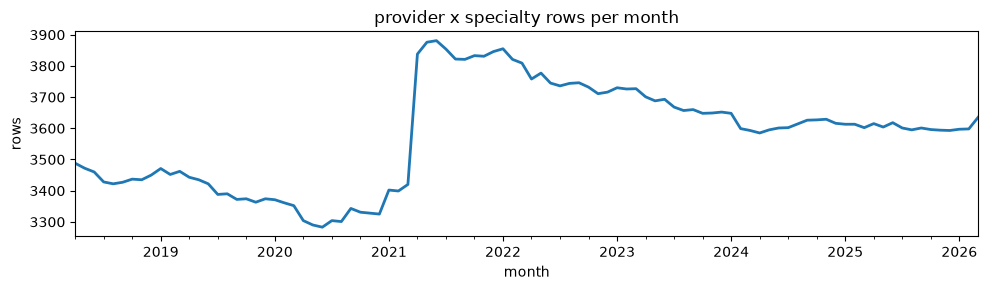

In [16]:
# coverage counts + how the panel size moves month to month
print("months    :", panel["month"].nunique())
print("providers :", panel["provider_code"].nunique())
print("tfuncs    :", panel["tfunc_code"].nunique())
print("rows      :", len(panel))

panel.groupby("month").size().plot(figsize=(10, 3), linewidth=2,
                                   title="provider x specialty rows per month")
plt.ylabel("rows")
plt.tight_layout()
plt.show()


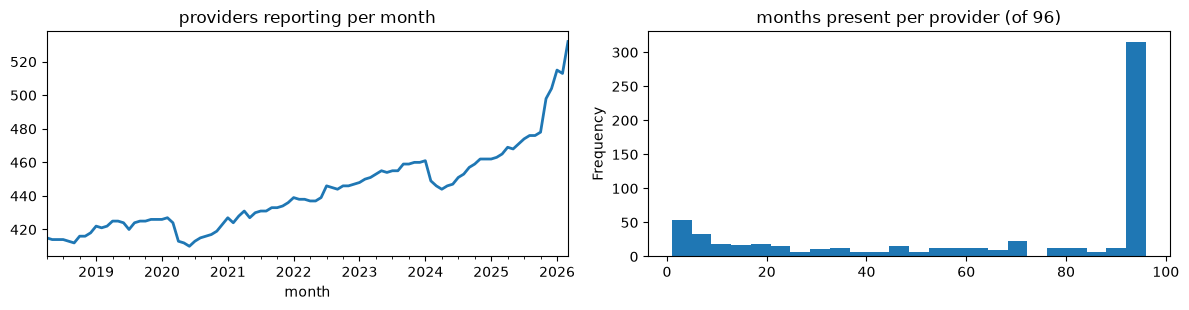

In [17]:
# provider churn: how many report each month, and how long each one stays in the data
fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
panel.groupby("month")["provider_code"].nunique().plot(ax=ax[0], linewidth=2,
                                                       title="providers reporting per month")
panel.groupby("provider_code")["month"].nunique().plot(kind="hist", bins=24, ax=ax[1],
                                                       title="months present per provider (of 96)")
plt.tight_layout()
plt.show()


In [18]:
# which specialties carry the waiting list; denominator = all patient-months in the panel
share = panel.groupby("tfunc_code")["total_waiting"].sum().sort_values(ascending=False)
(share / share.sum() * 100).round(1)


tfunc_code
C_110    11.6
C_130     9.1
C_120     8.0
C_502     7.4
C_100     6.4
X02       5.9
X01       5.5
C_101     5.5
C_330     5.2
C_301     5.2
C_320     5.0
X05       4.6
C_140     4.2
X04       3.6
C_400     3.0
C_340     2.6
C_410     1.8
X06       1.7
C_160     1.4
C_150     0.8
C_300     0.7
C_430     0.4
C_170     0.2
X03       0.1
Name: total_waiting, dtype: float64

## 10. National trend

Everything summed to one England-wide series per month: the total incomplete waiting list, then the share waiting over 18 and over 52 weeks (denominator = that month's total waiting list).

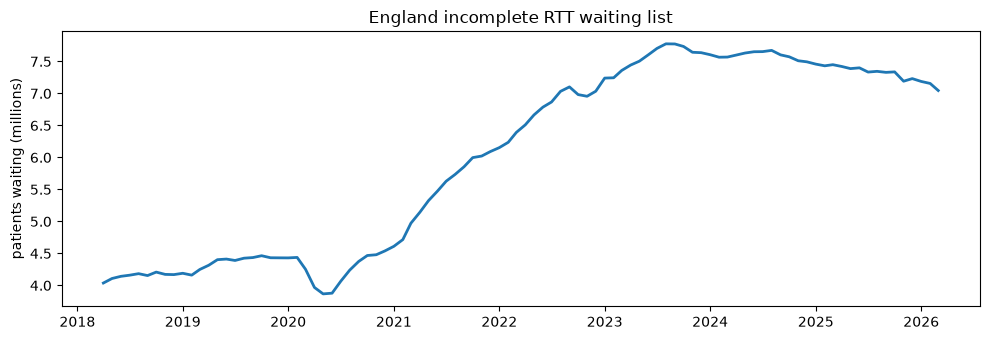

In [19]:
# national monthly totals across all providers and specialties
nat = panel.groupby("month")[["total_waiting", "gt18", "gt52"]].sum()

plt.figure(figsize=(10, 3.5))
plt.plot(nat.index, nat["total_waiting"] / 1e6, linewidth=2)
plt.title("England incomplete RTT waiting list")
plt.ylabel("patients waiting (millions)")
plt.tight_layout()
plt.show()


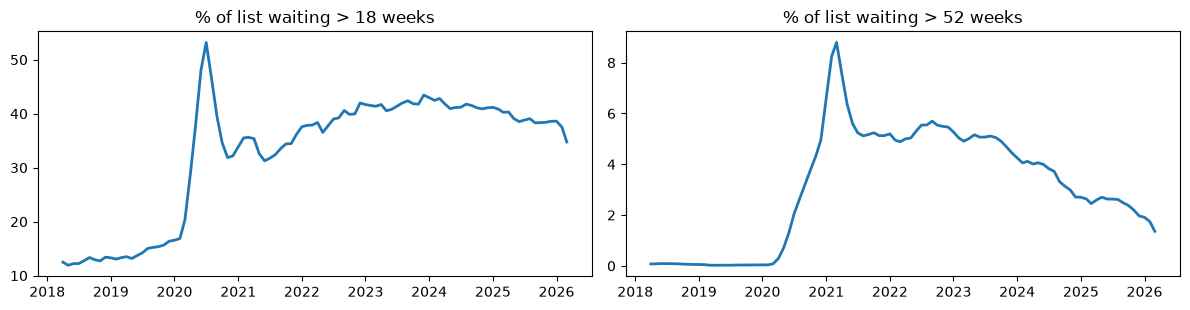

In [20]:
# long-wait shares; denominator = that month's total incomplete waiting list
nat["pct_gt18"] = nat["gt18"] / nat["total_waiting"]
nat["pct_gt52"] = nat["gt52"] / nat["total_waiting"]

fig, ax = plt.subplots(1, 2, figsize=(12, 3.2), sharex=True)   # two panels, one series each
ax[0].plot(nat.index, nat["pct_gt18"] * 100, linewidth=2)
ax[0].set_title("% of list waiting > 18 weeks")
ax[1].plot(nat.index, nat["pct_gt52"] * 100, linewidth=2)
ax[1].set_title("% of list waiting > 52 weeks")
plt.tight_layout()
plt.show()


## 11. One provider × one specialty

The single biggest provider–specialty cell over the whole period, as a concrete series — this is the granularity any forecasting model would work at.

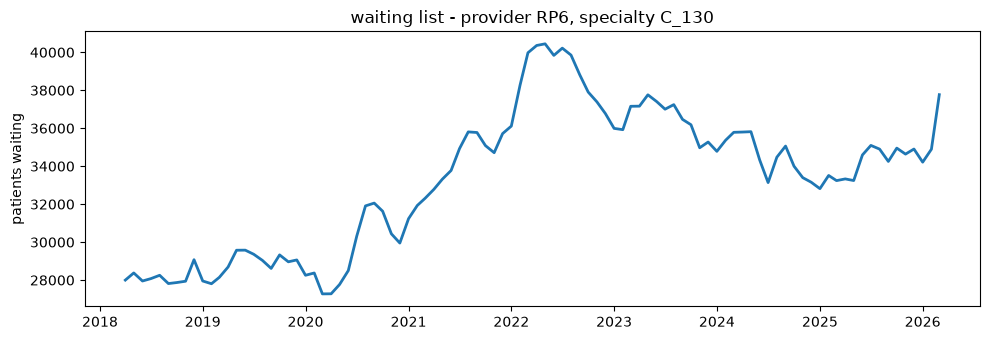

In [21]:
# pick the provider x specialty pair with the largest total waiting over all months
top = panel.groupby(["provider_code", "tfunc_code"])["total_waiting"].sum().idxmax()
one = panel[(panel["provider_code"] == top[0]) & (panel["tfunc_code"] == top[1])].sort_values("month")

plt.figure(figsize=(10, 3.5))
plt.plot(one["month"], one["total_waiting"], linewidth=2)
plt.title(f"waiting list - provider {top[0]}, specialty {top[1]}")
plt.ylabel("patients waiting")
plt.tight_layout()
plt.show()


## 12. Pre vs post Covid

Cutoff March 2020 (first lockdown month). Means of the national series either side; the pct columns are shares of each month's total waiting list.

In [22]:
import numpy as np

era = np.where(nat.index < pd.Timestamp("2020-03-01"), "pre_covid", "post_covid")
nat.groupby(era)[["total_waiting", "pct_gt18", "pct_gt52"]].mean().round(3)


,total_waiting,pct_gt18,pct_gt52
post_covid,6574295.781,0.388,0.041
pre_covid,4283000.478,0.139,0.001


## 13. Core file for modeling

The panel plus per-row long-wait shares, saved to `data/processed/`. This is the file later notebooks start from instead of re-reading 8 GB of csvs.

In [23]:
from pathlib import Path

PROC = Path("../data/processed")
PROC.mkdir(exist_ok=True)

# per-row shares; denominator = that row's total_waiting.
# np.where guards rows with total_waiting == 0, where plain division gives a silent inf/nan
panel["pct_gt18"] = np.where(panel["total_waiting"] > 0, panel["gt18"] / panel["total_waiting"], 0.0)
panel["pct_gt52"] = np.where(panel["total_waiting"] > 0, panel["gt52"] / panel["total_waiting"], 0.0)

panel.to_csv(PROC / "rtt_incomplete_panel.csv", index=False)
print(panel.shape, "->", PROC / "rtt_incomplete_panel.csv")


(343441, 8) -> ..\data\processed\rtt_incomplete_panel.csv
